In [138]:
import pandas as pd
from matplotlib.pyplot import boxplot

In [139]:
df = pd.read_csv("cleaned_data.csv")

In [140]:
Q1 = df.quantile(0.25,numeric_only=True)
Q3 = df.quantile(0.75,numeric_only=True)
IQR = Q3 - Q1
min_ = Q1 - 1.5*IQR
max_ = Q3 + 1.5*IQR

{'whiskers': [<matplotlib.lines.Line2D at 0x24a15d3b390>,
 'caps': [<matplotlib.lines.Line2D at 0x24a15d3b610>,
 'boxes': [<matplotlib.lines.Line2D at 0x24a15d3b250>],
 'medians': [<matplotlib.lines.Line2D at 0x24a15d3b890>],
 'fliers': [<matplotlib.lines.Line2D at 0x24a15d3b9d0>],
 'means': []}

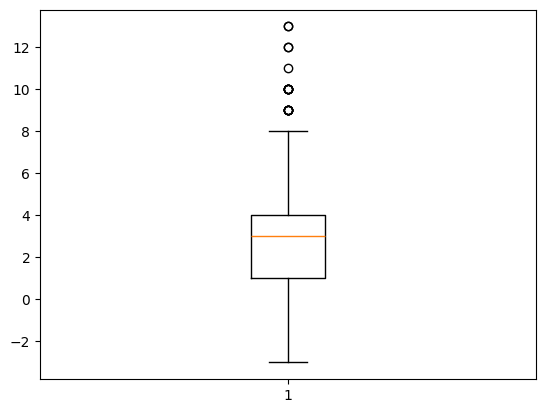

In [142]:
boxplot(df.floor)

In [ ]:
def newDf(df,colName,min,max):
    """
    min ve max degerleri arasindaki verileri yeni bir data frame olarak dondurur.

    parameters
    df = data frame
    colName = column Name (sutun ismi)
    min = Q1 - 1.5*IQR formulunden gelen min degeri
    max = Q3 + 1.5*IQR formulunden gleen max degeri
    """
    return df[(df[colName] > min[colName]) & (df[colName] < max[colName])]

In [144]:
columns = ['room','age','price','area','floor']

try:
    for col in columns:
        df = newDf(df,col,min_,max_)
except Exception as e:
    print(e)

living room min max degerlerinin ikisi de 1 oldugu icin onu eklemiyoruz eger eklersek data frame'de hic veri kalmiyor.

In [145]:
df.to_csv('statistically_cleaned_data.csv',index=False)